# Module 08, Part 5: Choosing between VAEs, GANs and diffusion

This notebook is the runnable companion to Part 5 of the Module 08 learning content. It puts the three families side by side on the same data, with the same scoring, and checks:

1. Quality and coverage: Fréchet distance, precision and recall of 359 generated digits against the 359 test digits, for every seed.
2. Whether any model copies the training set (nearest-training-image distance) and whether the class mix of the samples matches the data.
3. What each costs: training time, network evaluations per sample, and the time to draw 359 samples.
4. Whether sample sharpness differs, using the mean distance of a pixel from 0.5.

All three models see the 1,438 training digits, and are scored with the feature network from Module 07. The VAE has an 8-dimensional code and a hidden layer of 64 units, trained for 200 epochs at beta 1. The GAN is the WGAN-GP of Part 2
(16 noise values, 128 hidden units, 4,000 generator steps, three critic steps each). The diffusion model is the one of Part 4 (256 hidden units, 100 steps, 4,000 training steps). Three seeds each, about 15 minutes in all.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
class VAE(nn.Module):
    """Gaussian encoder q(z|x), Bernoulli-on-intensity decoder p(x|z). With n_classes > 0 both networks also see a one-hot label."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, n_classes=0):
        super().__init__()
        self.d_latent, self.n_classes = d_latent, n_classes
        self.enc = nn.Sequential(nn.Linear(d_in + n_classes, d_hidden), nn.ReLU())
        self.mu = nn.Linear(d_hidden, d_latent)
        self.logvar = nn.Linear(d_hidden, d_latent)
        self.dec = nn.Sequential(nn.Linear(d_latent + n_classes, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, c=None):
        """Returns logits; apply a sigmoid to get pixel intensities."""
        return self.dec(z if c is None else torch.cat([z, c], 1))

    @staticmethod
    def reparameterize(mu, logvar, generator=None):
        eps = torch.randn(mu.shape, generator=generator)
        return mu + torch.exp(0.5 * logvar) * eps

    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, c), mu, logvar


def kl_to_standard_normal(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) summed over latent dimensions, one value per example."""
    return 0.5 * (mu ** 2 + torch.exp(logvar) - 1.0 - logvar).sum(1)


def reconstruction_nll(logits, x):
    """Bernoulli negative log-likelihood of the pixel intensities, summed over pixels, one value per example."""
    return F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)


def elbo_terms(model, x, c=None):
    """One-sample estimate of the two terms of the negative ELBO, each averaged over the batch."""
    logits, mu, logvar = model(x, c)
    return reconstruction_nll(logits, x).mean(), kl_to_standard_normal(mu, logvar).mean()


def train_vae(model, X, y_onehot=None, epochs=200, lr=2e-3, batch_size=64, beta=1.0, anneal_epochs=0, seed=0):
    """Minimize recon + beta * KL. With anneal_epochs > 0, beta rises linearly from 0 to its final value over that many epochs.
    Returns a list of (reconstruction, KL) epoch averages."""
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        b = beta * min(1.0, ep / anneal_epochs) if anneal_epochs > 0 else beta
        perm = torch.randperm(len(X), generator=g)
        sr = sk = 0.0
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            xb = X[idx]
            cb = y_onehot[idx] if y_onehot is not None else None
            rec, kl = elbo_terms(model, xb, cb)
            loss = rec + b * kl
            opt.zero_grad()
            loss.backward()
            opt.step()
            sr += rec.item() * len(xb)
            sk += kl.item() * len(xb)
        hist.append((sr / len(X), sk / len(X)))
    return hist


@torch.no_grad()
def evaluate_terms(model, X, c=None, repeats=10, seed=0):
    """Average (reconstruction, KL) over the set, using several draws of z per example."""
    torch.manual_seed(seed)
    r = k = 0.0
    for _ in range(repeats):
        rec, kl = elbo_terms(model, X, c)
        r += rec.item() / repeats
        k += kl.item() / repeats
    return r, k


@torch.no_grad()
def iwae_bound(model, x, K=1, seed=0):
    """Importance-weighted estimate of log p(x) per example, using q(z|x) as the proposal and K samples.
    K = 1 is the ELBO. As K grows the bound tightens toward log p(x)."""
    torch.manual_seed(seed)
    mu, logvar = model.encode(x)
    std = torch.exp(0.5 * logvar)
    logw = []
    for _ in range(K):
        z = mu + std * torch.randn_like(std)
        logits = model.decode(z)
        log_px_z = -reconstruction_nll(logits, x)
        log_pz = -0.5 * (z ** 2 + math.log(2 * math.pi)).sum(1)
        log_qz = -0.5 * (((z - mu) / std) ** 2 + math.log(2 * math.pi) + logvar).sum(1)
        logw.append(log_px_z + log_pz - log_qz)
    logw = torch.stack(logw, 0)
    return torch.logsumexp(logw, 0) - math.log(K)


@torch.no_grad()
def active_units(model, X, threshold=0.01):
    """Number of latent dimensions whose posterior mean varies across the data by more than the threshold (variance)."""
    mu, _ = model.encode(X)
    return int((mu.var(0) > threshold).sum().item())

In [4]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(d_in, d_out, d_hidden=64, layers=2, act=nn.ReLU, spectral=False):
    mods, d = [], d_in
    for _ in range(layers):
        lin = nn.Linear(d, d_hidden)
        mods += [nn.utils.spectral_norm(lin) if spectral else lin, act()]
        d = d_hidden
    last = nn.Linear(d, d_out)
    mods.append(nn.utils.spectral_norm(last) if spectral else last)
    return nn.Sequential(*mods)


class Generator(nn.Module):
    """Maps noise (and an optional one-hot label) to a sample. out_act='sigmoid' for images in [0, 1], None for raw coordinates."""

    def __init__(self, d_noise=8, d_out=2, d_hidden=64, n_classes=0, out_act=None):
        super().__init__()
        self.d_noise, self.n_classes = d_noise, n_classes
        self.net = mlp(d_noise + n_classes, d_out, d_hidden)
        self.out_act = out_act

    def forward(self, z, c=None):
        out = self.net(z if c is None else torch.cat([z, c], 1))
        return torch.sigmoid(out) if self.out_act == "sigmoid" else out


class Discriminator(nn.Module):
    """Returns a logit (a real-valued score for the Wasserstein critic). With n_classes > 0 it also sees the label."""

    def __init__(self, d_in=2, d_hidden=64, n_classes=0, spectral=False):
        super().__init__()
        self.net = mlp(d_in + n_classes, 1, d_hidden, act=lambda: nn.LeakyReLU(0.2), spectral=spectral)

    def forward(self, x, c=None):
        return self.net(x if c is None else torch.cat([x, c], 1)).squeeze(1)


def gradient_penalty(D, real, fake, c=None):
    """WGAN-GP: penalize the critic's gradient norm, measured on random points between real and fake, for deviating from 1."""
    t = torch.rand(len(real), 1)
    x = (t * real + (1 - t) * fake).requires_grad_(True)
    g, = torch.autograd.grad(D(x, c).sum(), x, create_graph=True)
    return ((g.norm(dim=1) - 1) ** 2).mean(), g.norm(dim=1).mean().item()


def train_gan(G, D, X, y_onehot=None, objective="nonsat", steps=2000, batch_size=128, lr_g=2e-3, lr_d=2e-3,
              n_critic=1, gp_weight=10.0, seed=0, betas=(0.5, 0.9), log_every=0):
    """Alternate discriminator and generator updates.
    objective: 'minimax'  generator minimizes log(1 - D(G(z)))   (the original, saturating loss)
               'nonsat'   generator maximizes log D(G(z))        (the standard fix)
               'wgan_gp'  critic maximizes D(real) - D(fake) with a gradient penalty, generator maximizes D(G(z))
    Returns a dict of histories: d_loss, g_loss, d_real (mean probability or score on real), d_fake, g_grad (norm of the loss gradient at the generator output)."""
    torch.manual_seed(seed)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=betas)
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=betas)
    h = {"d_loss": [], "g_loss": [], "d_real": [], "d_fake": [], "g_grad": [], "gp_norm": []}
    n = len(X)
    for step in range(steps):
        for _ in range(n_critic):
            idx = torch.randint(0, n, (batch_size,))
            real = X[idx]
            c = None if y_onehot is None else y_onehot[idx]
            with torch.no_grad():
                fake = G(torch.randn(batch_size, G.d_noise), c)
            dr, df = D(real, c), D(fake, c)
            if objective == "wgan_gp":
                gp, gpn = gradient_penalty(D, real, fake, c)
                d_loss = df.mean() - dr.mean() + gp_weight * gp
                h["gp_norm"].append(gpn)
            else:
                d_loss = F.binary_cross_entropy_with_logits(dr, torch.ones_like(dr)) + \
                         F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))
            opt_d.zero_grad(); d_loss.backward(); opt_d.step()
        idx = torch.randint(0, n, (batch_size,))
        c = None if y_onehot is None else y_onehot[idx]
        fake = G(torch.randn(batch_size, G.d_noise), c)
        fake.retain_grad()
        df = D(fake, c)
        if objective == "minimax":
            g_loss = -F.binary_cross_entropy_with_logits(df, torch.zeros_like(df))   # = log(1 - D(G(z)))
        elif objective == "nonsat":
            g_loss = F.binary_cross_entropy_with_logits(df, torch.ones_like(df))     # = -log D(G(z))
        else:
            g_loss = -df.mean()
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()
        h["d_loss"].append(float(d_loss.detach())); h["g_loss"].append(float(g_loss.detach()))
        h["g_grad"].append(float(fake.grad.norm(dim=1).mean()))
        if objective == "wgan_gp":
            h["d_real"].append(float(dr.mean().detach())); h["d_fake"].append(float(df.mean().detach()))
        else:
            h["d_real"].append(float(torch.sigmoid(dr).mean().detach())); h["d_fake"].append(float(torch.sigmoid(df).mean().detach()))
    return h


@torch.no_grad()
def sample_gan(G, n, seed=0, label=None):
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, G.d_noise, generator=g)
    c = None if G.n_classes == 0 else torch.nn.functional.one_hot(torch.full((n,), label), G.n_classes).float()
    return G(z, c)

In [5]:
import math
import torch
import torch.nn as nn


class Schedule:
    """Linear beta schedule. alpha_bar[t] is the share of the original signal left at step t."""

    def __init__(self, T=100, beta_min=1e-4, beta_max=0.1):
        self.T = T
        self.betas = torch.linspace(beta_min, beta_max, T)
        self.alphas = 1 - self.betas
        self.alpha_bar = torch.cumprod(self.alphas, 0)


def q_sample(sched, x0, t, noise=None):
    """Jump straight to step t of the forward process: x_t = sqrt(alpha_bar) x0 + sqrt(1 - alpha_bar) eps."""
    noise = torch.randn_like(x0) if noise is None else noise
    ab = sched.alpha_bar[t][:, None]
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise


class Denoiser(nn.Module):
    """Predicts the noise that was added, given the noisy input, the step, and an optional one-hot label."""

    def __init__(self, d_data=2, d_hidden=128, T=100, n_classes=0):
        super().__init__()
        self.T, self.n_classes = T, n_classes
        self.net = nn.Sequential(nn.Linear(d_data + 16 + n_classes, d_hidden), nn.SiLU(),
                                 nn.Linear(d_hidden, d_hidden), nn.SiLU(),
                                 nn.Linear(d_hidden, d_hidden), nn.SiLU(),
                                 nn.Linear(d_hidden, d_data))

    @staticmethod
    def time_features(t, T):
        freqs = torch.exp(torch.linspace(0, math.log(100.0), 8))
        a = (t.float()[:, None] / T) * freqs[None]
        return torch.cat([torch.sin(a), torch.cos(a)], 1)

    def forward(self, x, t, c=None):
        h = [x, self.time_features(t, self.T)] + ([] if c is None else [c])
        return self.net(torch.cat(h, 1))


def train_diffusion(model, sched, X, y_onehot=None, steps=3000, batch_size=128, lr=2e-3, seed=0):
    """Minimize the mean squared error between the true noise and the predicted noise at a random step."""
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = []
    for _ in range(steps):
        idx = torch.randint(0, len(X), (batch_size,))
        x0 = X[idx]
        t = torch.randint(0, sched.T, (batch_size,))
        xt, eps = q_sample(sched, x0, t)
        c = None if y_onehot is None else y_onehot[idx]
        loss = ((model(xt, t, c) - eps) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        losses.append(float(loss.detach()))
    return losses


@torch.no_grad()
def sample_ddpm(model, sched, n, d_data, seed=0, labels=None, return_path=False):
    """Ancestral sampling: start from pure noise and apply the learned reverse step T times."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, d_data, generator=g)
    c = None if labels is None else torch.nn.functional.one_hot(labels, model.n_classes).float()
    path = [x.clone()]
    for t in reversed(range(sched.T)):
        tt = torch.full((n,), t)
        eps = model(x, tt, c)
        a, ab, b = sched.alphas[t], sched.alpha_bar[t], sched.betas[t]
        mean = (x - b / (1 - ab).sqrt() * eps) / a.sqrt()
        x = mean + (b.sqrt() * torch.randn(x.shape, generator=g) if t > 0 else 0)
        if return_path: path.append(x.clone())
    return (x, path) if return_path else x


@torch.no_grad()
def sample_ddim(model, sched, n, d_data, n_steps=10, seed=0, labels=None):
    """Deterministic sampler that skips steps: the same trained network, n_steps evaluations instead of T."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, d_data, generator=g)
    c = None if labels is None else torch.nn.functional.one_hot(labels, model.n_classes).float()
    ts = torch.linspace(sched.T - 1, 0, n_steps).round().long()
    for i, t in enumerate(ts):
        ab = sched.alpha_bar[t]
        ab_next = sched.alpha_bar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        eps = model(x, torch.full((n,), int(t)), c)
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
        x = ab_next.sqrt() * x0 + (1 - ab_next).sqrt() * eps
    return x

In [6]:
import numpy as np
import torch
import torch.nn as nn
from scipy import linalg


class FeatureNet(nn.Module):
    """A small classifier trained on real digits. Its hidden layer plays the role Inception plays in FID."""

    def __init__(self, d_in=64, d_feat=32):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, d_feat), nn.ReLU())
        self.head = nn.Linear(d_feat, 10)

    def features(self, x):
        return self.body(x)

    def forward(self, x):
        return self.head(self.body(x))


def train_feature_net(X, y, epochs=60, seed=0):
    torch.manual_seed(seed)
    net = FeatureNet()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = nn.functional.cross_entropy(net(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net


@torch.no_grad()
def get_features(net, X):
    return net.features(X).numpy().astype(np.float64)


def frechet_distance(fa, fb):
    """Frechet distance between Gaussians fitted to two sets of features (the quantity behind FID)."""
    mu_a, mu_b = fa.mean(0), fb.mean(0)
    eps = 1e-6 * np.eye(fa.shape[1])
    ca, cb = np.cov(fa, rowvar=False) + eps, np.cov(fb, rowvar=False) + eps
    covmean = linalg.sqrtm(ca @ cb)
    covmean = covmean.real
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca) + np.trace(cb) - 2 * np.trace(covmean))


def _knn_radius(F, k):
    d = np.linalg.norm(F[:, None] - F[None], axis=-1)
    return np.sort(d, axis=1)[:, k]


def precision_recall(real, fake, k=3):
    """Precision: share of generated points that land inside the real data's neighbourhood.
    Recall: share of real points that land inside the generated data's neighbourhood. (k-nearest-neighbour balls.)"""
    r_real, r_fake = _knn_radius(real, k), _knn_radius(fake, k)
    d = np.linalg.norm(fake[:, None] - real[None], axis=-1)
    precision = float((d <= r_real[None]).any(1).mean())
    recall = float((d.T <= r_fake[None]).any(1).mean())
    return precision, recall


def nearest_train_distance(samples, train):
    """Pixel-space distance from each generated image to its nearest training image. Near zero means copying."""
    d = torch.cdist(samples, train)
    return d.min(1).values

In [7]:
Xtr, ytr, Xte, yte = load_data()
net = train_feature_net(Xtr, ytr)
fte = get_features(net, Xte)
sched = Schedule(T=100)

## 1. Train and sample each model

For each seed we train all three, draw 359 samples from each, and record the wall-clock time of training and of sampling. The sampling cost is also reported as the number of times the network is evaluated per sample, which does not depend on the machine.

In [8]:
def score(s):
    f = get_features(net, s)
    p, r = precision_recall(fte, f)
    counts = np.bincount(net(s).argmax(1).numpy(), minlength=10)
    return dict(fd=frechet_distance(f, fte), p=p, r=r, nn=nearest_train_distance(s, Xtr).mean().item(),
                sharp=(s - 0.5).abs().mean().item(), counts=counts)

res = {"VAE": [], "GAN": [], "Diffusion": []}
for seed in range(3):
    # VAE
    t0 = time.time(); v = VAE(d_latent=8); train_vae(v, Xtr, epochs=200, beta=1.0, seed=seed); tt = time.time() - t0
    t0 = time.time()
    with torch.no_grad():
        s = torch.sigmoid(v.decode(torch.randn(359, 8, generator=torch.Generator().manual_seed(9))))
    res["VAE"].append(dict(score(s), train_s=tt, sample_s=time.time() - t0, evals=1, samples=s))
    # GAN
    torch.manual_seed(seed)
    G = Generator(d_noise=16, d_out=64, d_hidden=128, out_act="sigmoid"); D = Discriminator(d_in=64, d_hidden=128)
    t0 = time.time()
    train_gan(G, D, Xtr, objective="wgan_gp", steps=4000, lr_g=5e-4, lr_d=5e-4, n_critic=3, betas=(0.5, 0.999), seed=seed); tt = time.time() - t0
    t0 = time.time(); s = sample_gan(G, 359, seed=9)
    res["GAN"].append(dict(score(s), train_s=tt, sample_s=time.time() - t0, evals=1, samples=s))
    # Diffusion
    m = Denoiser(d_data=64, d_hidden=256, T=100); t0 = time.time()
    train_diffusion(m, sched, Xtr * 2 - 1, steps=4000, lr=1e-3, seed=seed); tt = time.time() - t0
    t0 = time.time(); s = ((sample_ddpm(m, sched, 359, 64, seed=9) + 1) / 2).clamp(0, 1)
    res["Diffusion"].append(dict(score(s), train_s=tt, sample_s=time.time() - t0, evals=100, samples=s))
    print(f"seed {seed} done", flush=True)

seed 0 done


seed 1 done


seed 2 done


## 2. Quality, coverage and copying

Fréchet distance is lower-is-better. Precision asks whether the generated images look like real ones, recall asks whether the real images are covered. The nearest-training-image distance is a copying check:
the real test images' own distance to their nearest training image is printed first, so a generator whose samples sit much closer than that is memorizing.

In [9]:
real_nn = nearest_train_distance(Xte, Xtr).mean().item()
print(f"nearest training image for real test digits: {real_nn:.2f}   decisiveness of real digits: {(Xte - 0.5).abs().mean():.3f}\n")
print("model       seed   Frechet   precision   recall   nearest train   decisiveness")
for name, runs in res.items():
    for seed, r in enumerate(runs):
        print(f"{name:10s}  {seed:4d}   {r['fd']:7.1f}   {r['p']:9.2f}   {r['r']:6.2f}   {r['nn']:13.2f}   {r['sharp']:12.3f}")
print("\nmean over seeds")
print("model       Frechet   precision   recall   nearest train   decisiveness")
for name, runs in res.items():
    g = lambda k: np.mean([r[k] for r in runs])
    print(f"{name:10s}  {g('fd'):7.1f}   {g('p'):9.2f}   {g('r'):6.2f}   {g('nn'):13.2f}   {g('sharp'):12.3f}")

nearest training image for real test digits: 1.07   decisiveness of real digits: 0.395

model       seed   Frechet   precision   recall   nearest train   decisiveness
VAE            0      12.6        0.91     0.49            1.13          0.344
VAE            1      15.4        0.91     0.41            1.15          0.342
VAE            2      11.8        0.89     0.43            1.13          0.343
GAN            0       6.2        0.77     0.91            1.31          0.396
GAN            1       3.8        0.76     0.91            1.31          0.401
GAN            2       5.3        0.75     0.90            1.33          0.397
Diffusion      0      10.3        0.77     0.84            1.48          0.336
Diffusion      1      10.7        0.72     0.85            1.49          0.337
Diffusion      2      11.1        0.76     0.86            1.49          0.338

mean over seeds
model       Frechet   precision   recall   nearest train   decisiveness
VAE            13.2        0.90  

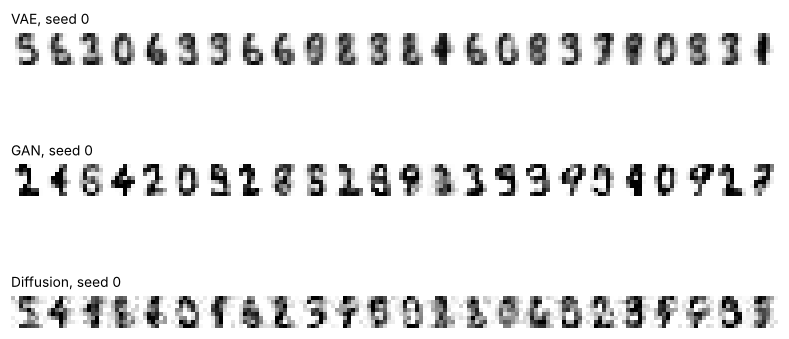

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(9, 4.4))
for ax, name in zip(axes, res):
    ax.imshow(np.concatenate(list(res[name][0]["samples"][:24].reshape(-1, 8, 8)), 1), cmap="gray_r"); ax.axis("off"); ax.set_title(f"{name}, seed 0", fontsize=9, loc="left")
plt.show()

## 3. Is the class mix right?

A model can score well on average and still over-produce some digits. The feature network assigns each generated image to a digit, and we compare the counts with the 359 test images. The measure is the total variation distance between the
two class distributions (half the sum of absolute differences of the shares, zero for identical mixes).

In [11]:
real_share = np.bincount(yte.numpy(), minlength=10) / len(yte)
print("class counts of the test images:", np.bincount(yte.numpy(), minlength=10).tolist())
for name, runs in res.items():
    tv = [0.5 * np.abs(r["counts"] / 359 - real_share).sum() for r in runs]
    print(f"{name:10s} total variation distance by seed {[round(float(t), 3) for t in tv]}   seed 0 counts {runs[0]['counts'].tolist()}")

class counts of the test images: [27, 35, 36, 29, 30, 40, 44, 39, 38, 41]
VAE        total variation distance by seed [0.095, 0.181, 0.05]   seed 0 counts [28, 29, 41, 40, 29, 32, 47, 32, 52, 29]
GAN        total variation distance by seed [0.117, 0.123, 0.145]   seed 0 counts [55, 38, 44, 21, 33, 36, 37, 35, 33, 27]
Diffusion  total variation distance by seed [0.123, 0.117, 0.109]   seed 0 counts [39, 44, 31, 43, 25, 31, 38, 27, 47, 34]


## 4. What each one costs

Training time is wall-clock on this machine's CPU, with the training budgets stated at the top of the notebook (which were chosen to be comparable in effort, not equal in anything exact). The sampling cost in network evaluations is a property of the method.

In [12]:
print("model       train seconds (mean)   evaluations per sample   seconds for 359 samples (mean)")
for name, runs in res.items():
    print(f"{name:10s}  {np.mean([r['train_s'] for r in runs]):19.0f}   {runs[0]['evals']:22d}   {np.mean([r['sample_s'] for r in runs]):28.3f}")

model       train seconds (mean)   evaluations per sample   seconds for 359 samples (mean)
VAE                           6                        1                          0.063
GAN                          36                        1                          0.050
Diffusion                    10                      100                          0.160


## 5. Reading the table

No model wins on every column, and which column matters depends on the use. A quick way to keep the three apart:

- The VAE is cheap to train, draws a sample in one pass and has a smooth, usable latent space (Module 07), at the price of samples that are less sharp.
- The GAN also draws a sample in one pass and its samples are sharp, but it is the hardest to train and the model most likely to drop part of the data.
- Diffusion is the most reliable to train and the best at covering the data, at the price of many network evaluations per sample.

Check each of those three sentences against your own numbers above before relying on them. The experiments use 8 by 8 digits and small networks, so the size of each difference is specific to this setting.